In [2]:
# =====================================
# CNN1D FULLY SEGMENT EXPERIMENT
# =====================================

import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.run.model.run_hmm_cnn_mamba_classifier import RunHmmCnnMambaClassifier
from src.run.preprocess.config import _project_path


=== Running experiment with n_iter=50 ===

START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training Mamba model...
Fold 01 | Epoch 01 | train_loss=0.6720 | train_accuracy=0.7167 | train_f1=0.6909 | train_auc=0.8209 | train_precision=0.7308 | train_recall=0.6552 | train_specificity=0.7742 | val_loss=0.6949 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.5357 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=0.7606 | train_accuracy=0.5167 | train_f1=0.0000 | train_auc=0.8298 | train_precision=0.0000 | train_recall=0.0000 | train_specificity=1.0000 | val_loss=0.7995 | val_accuracy=0.4667 | val_f1=0.0000 | val_auc=0.6607 | val_precision=0.0000 | val_recall=0.0000 | val_specificity=1.0000
Fold 01 | Epoch 03 | train_loss=0.68

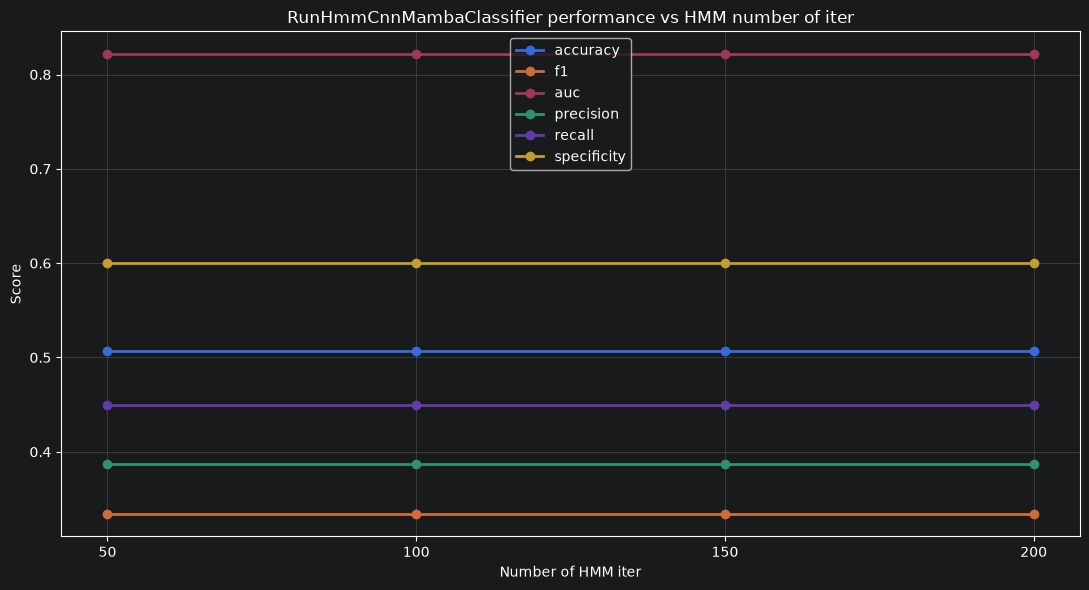


=== BEST HMM N_ITER ===
n_iter: 50
Accuracy: 0.5067
F1: 0.3345
AUC: 0.8214
Precision: 0.3867
Recall: 0.4500
Specificity: 0.6000


In [3]:
# HMM N_ITER

n_iter = [50, 100, 150, 200]

results = []

for i in n_iter:

    print(
        f"\n=== Running experiment with n_iter={i} ==="
    )

    runner = RunHmmCnnMambaClassifier(
        data_root=_project_path(
            "PaHaW/PaHaW/PaHaW_public"
        ),

        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================

        tasks=[4, 8],

        feature_names=("x", "y"),

        engineered_features=(
            "speed", "pressure_derivative",
        ),

        # =====================================================
        # Training
        # =====================================================

        epochs=50,

        batch_size=16,

        learning_rate=1e-3,

        regularization=1e-4,

        # =====================================================
        # HMM
        # =====================================================

        n_states=2,
        covariance_type="diag",
        n_iter=i,
        tol=1e-4,
        random_state=42,
        algorithm="viterbi",
        verbose=False,

        n_splits=5,

        normalize=True,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"hmm_cnn_mamba(train seg - val no)/"
            f"hmm_n_iter/iter_{i}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),

            "min_delta": 0.0,

            "normalize": True,

            "normalization_eps": 1e-6,

            "results_writer": "csv",

            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "n_iter": i,
    }

    row.update(
        summary["averages"]
    )

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values(
    "n_iter"
)

print("\n=== Summary ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "hmm_cnn_mamba_n_iter_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["n_iter"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(
    df["n_iter"]
)

plt.xlabel("Number of HMM iter")

plt.ylabel("Score")

plt.title(
    "RunHmmCnnMambaClassifier performance vs HMM number of iter"
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_auc",
    ascending=False
).iloc[0]

print("\n=== BEST HMM N_ITER ===")

print(
    f"n_iter: {int(best['n_iter'])}"
)

print(
    f"Accuracy: {best['val_accuracy']:.4f}"
)

print(
    f"F1: {best['val_f1']:.4f}"
)

print(
    f"AUC: {best['val_auc']:.4f}"
)

print(
    f"Precision: {best['val_precision']:.4f}"
)

print(
    f"Recall: {best['val_recall']:.4f}"
)

print(
    f"Specificity: {best['val_specificity']:.4f}"
)

In [ ]:
# HMM TOL

tols = [1e-2, 1e-3, 1e-4, 1e-5]

results = []

for t in tols:

    print(
        f"\n=== Running experiment with tol={t} ==="
    )

    runner = RunHmmCnnMambaClassifier(
        data_root=_project_path(
            "PaHaW/PaHaW/PaHaW_public"
        ),

        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================

        tasks=[4, 8],

        feature_names=("x", "y"),

        engineered_features=(
            "speed", "pressure_derivative",
        ),

        # =====================================================
        # Training
        # =====================================================

        epochs=50,

        batch_size=16,

        learning_rate=1e-3,

        regularization=1e-4,

        # =====================================================
        # HMM
        # =====================================================

        n_states=2,
        covariance_type="diag",
        n_iter=50,
        tol=t,
        random_state=42,
        algorithm="viterbi",
        verbose=False,

        n_splits=5,

        normalize=True,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"hmm_cnn_mamba(train seg - val no)/"
            f"hmm_tol/tol_{t}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),

            "min_delta": 0.0,

            "normalize": True,

            "normalization_eps": 1e-6,

            "results_writer": "csv",

            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "tol": t,
    }

    row.update(
        summary["averages"]
    )

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values(
    "tol"
)

print("\n=== Summary ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "hmm_cnn_mamba_tol_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["tol"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(
    df["tol"]
)

plt.xlabel("Number of HMM tolerances")
plt.ylabel(metric)
plt.legend()
plt.tight_layout()

plt.ylabel("Score")

plt.title(
    "RunHmmCnnMambaClassifier performance vs HMM number of tol"
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_auc",
    ascending=False
).iloc[0]

print("\n=== BEST HMM TOL ===")

print(
    f"tol: {int(best['tol'])}"
)

print(
    f"Accuracy: {best['val_accuracy']:.4f}"
)

print(
    f"F1: {best['val_f1']:.4f}"
)

print(
    f"AUC: {best['val_auc']:.4f}"
)

print(
    f"Precision: {best['val_precision']:.4f}"
)

print(
    f"Recall: {best['val_recall']:.4f}"
)

print(
    f"Specificity: {best['val_specificity']:.4f}"
)


=== Running experiment with tol=0.01 ===

START PATIENT-WISE K-FOLD CROSS VALIDATION
Total patients: 75
Folds: 5


FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
[Fold 01] Training Mamba model...
Fold 01 | Epoch 01 | train_loss=0.6721 | train_accuracy=0.7167 | train_f1=0.6909 | train_auc=0.8220 | train_precision=0.7308 | train_recall=0.6552 | train_specificity=0.7742 | val_loss=0.6950 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.5357 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 02 | train_loss=0.7607 | train_accuracy=0.5167 | train_f1=0.0000 | train_auc=0.8276 | train_precision=0.0000 | train_recall=0.0000 | train_specificity=1.0000 | val_loss=0.8003 | val_accuracy=0.4667 | val_f1=0.0000 | val_auc=0.6607 | val_precision=0.0000 | val_recall=0.0000 | val_specificity=1.0000
Fold 01 | Epoch 03 | train_loss=0.682